# Review 2 — Method 1

Member 5: forecasting and evaluation. **Member 3 Part A (STL, stationarity, change points, ITS) is a separate handoff and is not claimed as finished here.**

In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'config.yaml').exists())


## Part A — Akshay’s pattern analysis
Insert the reviewed M3 sections here when available.

## Part B — Complete weekly series and fixed evaluation design

In [2]:
TS = ROOT/'reports/review2/ts'
status=json.loads((TS/'run_status.json').read_text())
assert status['status']=='complete'
series=pd.read_csv(TS/'series_long.csv')
display(series.groupby('tag').size().rename('weeks').to_frame())
display(json.loads((TS/'series_manifest.json').read_text()))

,weeks
tag,
ALL,400
android,400
docker,400
excel,400
fastapi,400
java,400
javascript,400
openai-api,400
pandas,400


{'weeks': 400,
 'series': 14,
 'missing_weeks': 0,
 'origin_convention': 'first forecast week; training dates < origin',
 'monthly_rates': 'monthly_rates_masked.csv; never presented as weekly measurements',
 'tag_change': '100 * (forecast at week 26 / last observed weekly count - 1)',
 'interval_point': 'back-transformed median forecast, not arithmetic mean',
 'tag_classes': '< -40 steep decline; [-40,-10] declining; > -10 stabilising'}

## Training-only model selection
Orders use pre-July-2024 AIC; family selection uses 2024 H2. Backtest winners do not choose the final model.

In [3]:
display(pd.read_csv(TS/'model_choices.csv'))
display(pd.read_csv(TS/'validation_metrics.csv').head(20))

,tag,selected_model,p,q,validation_end,selection
0,ALL,sarimax,2,1,2024-12-31,lowest mean validation MASE across four horizo...
1,android,sarimax,1,1,2024-12-31,lowest mean validation MASE across four horizo...
2,docker,drift,1,1,2024-12-31,lowest mean validation MASE across four horizo...
3,excel,sarimax,1,1,2024-12-31,lowest mean validation MASE across four horizo...
4,fastapi,sarimax,1,2,2024-12-31,lowest mean validation MASE across four horizo...
5,java,sarimax,2,2,2024-12-31,lowest mean validation MASE across four horizo...
6,javascript,sarimax,2,1,2024-12-31,lowest mean validation MASE across four horizo...
7,openai-api,ets,1,1,2024-12-31,lowest mean validation MASE across four horizo...
8,pandas,sarimax,1,1,2024-12-31,lowest mean validation MASE across four horizo...
9,powerbi,naive,1,1,2024-12-31,lowest mean validation MASE across four horizo...


,tag,model,horizon,n_origins,mase,smape,coverage80,coverage95,naive_mase,log_rmse,skill_vs_naive
0,ALL,drift,1,7,0.249869,3.949045,0.714286,1.0,0.255199,0.051371,0.020886
1,ALL,drift,4,6,0.409521,6.194492,1.000000,1.0,0.548550,0.067193,0.253448
2,ALL,drift,13,4,1.184802,19.269580,1.000000,1.0,1.640632,0.201431,0.277838
3,ALL,drift,26,1,4.003834,75.739376,0.000000,0.0,4.936467,0.796892,0.188927
4,ALL,ets,1,7,0.255187,4.014522,0.714286,1.0,0.255199,0.053575,0.000047
5,ALL,ets,4,6,0.548387,8.286319,1.000000,1.0,0.548550,0.086606,0.000297
6,ALL,ets,13,4,1.640330,25.735275,0.500000,1.0,1.640632,0.264935,0.000184
7,ALL,ets,26,1,4.936111,85.808563,0.000000,0.0,4.936467,0.917246,0.000072
8,ALL,naive,1,7,0.255199,4.014674,0.714286,1.0,0.255199,0.053579,0.000000
9,ALL,naive,4,6,0.548550,8.288709,1.000000,1.0,0.548550,0.086628,0.000000


## Four-horizon backtest with three baselines
MASE uses each origin’s training naive scale. The comparison table uses identical successful origin/horizon cells. Failure records remain visible.

,model,horizon,n_series,mase,smape,log_rmse,skill_vs_naive,coverage80,coverage95
0,drift,1,14,0.218810,37.092532,0.406094,0.004197,0.491002,0.637369
1,drift,4,14,0.249477,37.991488,0.410250,0.044486,0.672216,0.856525
2,drift,13,14,0.387861,53.760766,0.587033,0.136868,0.704248,0.847044
3,drift,26,14,0.564213,74.611581,0.792137,0.222365,0.667347,0.833036
4,ets,1,14,0.189616,34.947434,0.346303,0.110113,0.493012,0.652675
5,ets,4,14,0.232430,38.255310,0.382306,0.093262,0.496178,0.693000
6,ets,13,14,0.387252,57.058210,0.573650,0.145557,0.413644,0.641518
7,ets,26,14,0.584449,77.056023,0.794480,0.212090,0.338435,0.596726
8,naive,1,14,0.219237,37.059830,0.405908,0.000000,0.487600,0.627474
9,naive,4,14,0.257885,38.474676,0.418104,0.000000,0.655021,0.852766


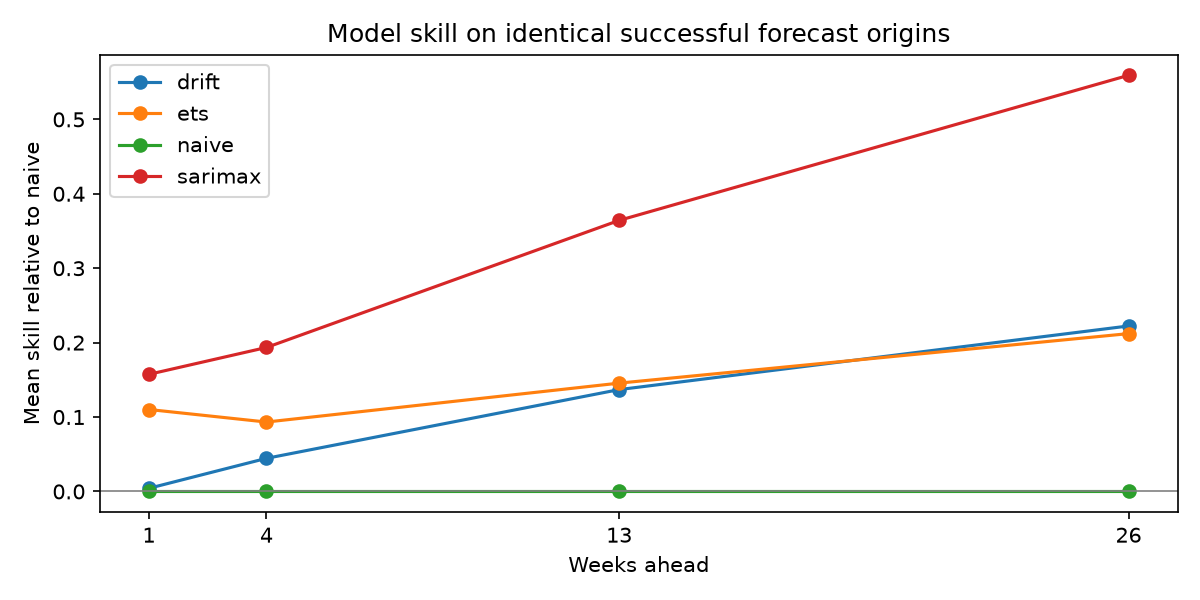

,tag,origin,model,error
0,docker,2024-12-17,sarimax,SARIMAX did not converge
1,java,2025-02-04,sarimax,SARIMAX did not converge
2,java,2025-10-14,sarimax,SARIMAX did not converge
3,javascript,2026-02-03,sarimax,SARIMAX did not converge
4,pandas,2025-09-16,sarimax,SARIMAX did not converge
5,powerbi,2025-03-04,sarimax,SARIMAX did not converge
6,python,2024-11-19,sarimax,SARIMAX did not converge
7,r,2025-07-22,sarimax,SARIMAX did not converge
8,r,2026-05-26,sarimax,SARIMAX did not converge
9,sql,2024-10-22,sarimax,SARIMAX did not converge


In [4]:
summary=pd.read_csv(TS/'backtest_summary_matched.csv')
display(summary)
display(Image(filename=str(TS/'backtest_skill.png')))
display(pd.read_csv(TS/'fit_failures.csv'))

## Statistical and residual checks
DM is a paired scaled-error comparison with HAC adjustment; results are exploratory on short overlapping horizons.

,tag,horizon,model,n,hac_lags,mean_loss_difference,statistic,p_value,loss,note
0,ALL,4,sarimax,21,0,-0.061834,-2.192647,0.040328,absolute count error / training naive scale,negative difference favours selected model; sm...
1,ALL,13,sarimax,19,3,-0.292556,-3.299749,0.003984,absolute count error / training naive scale,negative difference favours selected model; sm...
2,android,4,sarimax,21,0,-0.001032,-0.045222,0.964379,absolute count error / training naive scale,negative difference favours selected model; sm...
3,android,13,sarimax,19,3,-0.152198,-6.600920,0.000003,absolute count error / training naive scale,negative difference favours selected model; sm...
4,docker,4,drift,21,0,-0.012545,-2.055546,0.053118,absolute count error / training naive scale,negative difference favours selected model; sm...
5,docker,13,drift,19,3,-0.060340,-2.839268,0.010880,absolute count error / training naive scale,negative difference favours selected model; sm...
6,excel,4,sarimax,21,0,-0.028544,-1.089201,0.289016,absolute count error / training naive scale,negative difference favours selected model; sm...
7,excel,13,sarimax,19,3,-0.086314,-2.807052,0.011659,absolute count error / training naive scale,negative difference favours selected model; sm...
8,fastapi,4,sarimax,21,0,0.017165,0.276894,0.784703,absolute count error / training naive scale,negative difference favours selected model; sm...
9,fastapi,13,sarimax,19,3,-0.090580,-1.854142,0.080179,absolute count error / training naive scale,negative difference favours selected model; sm...


,tag,model,lag,lb_stat,lb_pvalue
0,ALL,sarimax,10,8.653720,5.652514e-01
1,ALL,sarimax,20,19.637850,4.807789e-01
2,android,sarimax,10,14.226747,1.628980e-01
3,android,sarimax,20,31.221753,5.233019e-02
4,docker,drift,10,285.397574,1.889874e-55
5,docker,drift,20,366.693585,1.602983e-65
6,excel,sarimax,10,12.711226,2.402686e-01
7,excel,sarimax,20,25.172063,1.949275e-01
8,fastapi,sarimax,10,17.110676,7.195059e-02
9,fastapi,sarimax,20,27.142745,1.312955e-01


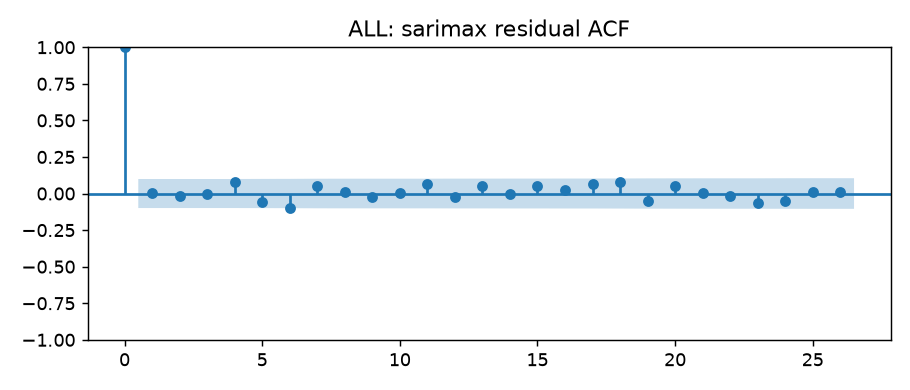

In [5]:
display(pd.read_csv(TS/'diebold_mariano.csv'))
display(pd.read_csv(TS/'residual_checks.csv'))
display(Image(filename=str(TS/'acf_ALL.png')))

## Forecasts through February 2027
Bands are labelled 80/95%; measured coverage may be much lower. The point is a back-transformed log median.

,weeks,last_date
tag,,
ALL,26,2027-02-23
android,26,2027-02-23
docker,26,2027-02-23
excel,26,2027-02-23
fastapi,26,2027-02-23
java,26,2027-02-23
javascript,26,2027-02-23
openai-api,26,2027-02-23
pandas,26,2027-02-23


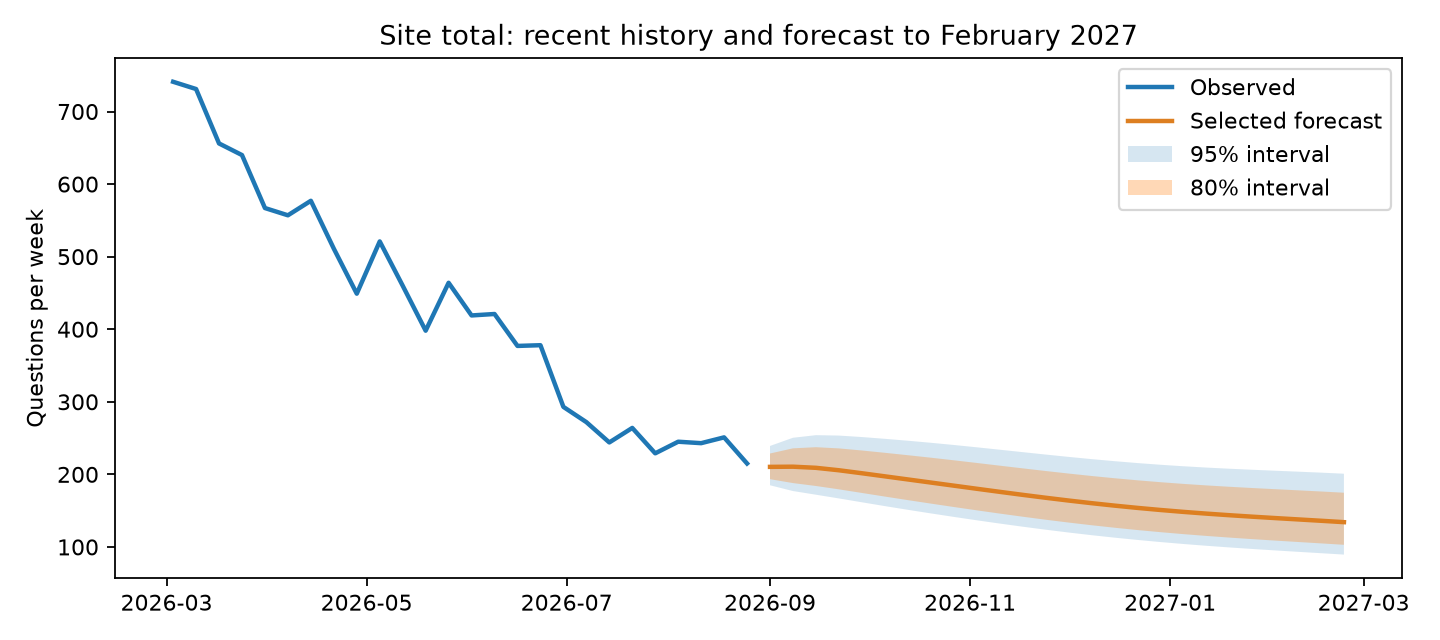

,tag,selected_model,change_26w_pct,forecast_class,last_week_count,forecast_week26,post2023_log_slope,half_life_weeks,load_index_vs_2025,its_slope_change_pct,its_status
0,ALL,sarimax,-37.601441,declining,215.0,134.156902,-0.023054,30.066454,8.275674,NaN,awaiting M3 its_results.csv
1,android,sarimax,-39.905595,declining,10.0,6.009441,-0.021246,32.624384,9.912092,NaN,awaiting M3 its_results.csv
2,docker,drift,-56.938927,steep decline,1.0,0.430611,-0.026917,25.751500,2.246084,NaN,awaiting M3 its_results.csv
3,excel,sarimax,-51.482362,steep decline,3.0,1.455529,-0.022823,30.370047,5.625702,NaN,awaiting M3 its_results.csv
4,fastapi,sarimax,-94.834287,steep decline,2.0,0.103314,-0.019011,36.460227,2.484432,NaN,awaiting M3 its_results.csv
5,java,sarimax,-39.253378,declining,15.0,9.111993,-0.022075,31.399048,11.241094,NaN,awaiting M3 its_results.csv
6,javascript,sarimax,-52.451019,steep decline,17.0,8.083327,-0.026787,25.875841,9.612978,NaN,awaiting M3 its_results.csv
7,openai-api,ets,NaN,not classifiable: zero baseline,0.0,0.000000,-0.020740,33.420984,0.000000,NaN,awaiting M3 its_results.csv
8,pandas,sarimax,-86.692805,steep decline,2.0,0.266144,-0.029112,23.809542,4.022757,NaN,awaiting M3 its_results.csv
9,powerbi,naive,NaN,not classifiable: zero baseline,0.0,0.000000,-0.021321,32.509587,0.000000,NaN,awaiting M3 its_results.csv


In [6]:
fc=pd.read_csv(TS/'forecasts_26w.csv')
display(fc[fc.selected].groupby('tag').agg(weeks=('horizon','size'),last_date=('week_start','max')))
display(Image(filename=str(TS/'forecast_ALL.png')))
display(pd.read_csv(TS/'tag_classes.csv'))

## Findings, handoff and remaining dependencies

In [7]:
print((ROOT/'reports/review2/m5_findings.md').read_text())
display(json.loads((TS/'dashboard_handoff.json').read_text()))

# Member 5: forecasting findings

- Models were selected on 2024 H2 validation; the expanding-window 2025–26 backtest uses first-forecast-week origins spaced four weeks apart.
- On matched origins, SARIMAX's mean 26-week skill versus naive is 55.9%; this is a retrospective model-family comparison, not a new selection from test results.
- Nominal 95% SARIMAX bands cover 52.0% of the 26-week endpoints on matched origins: intervals are too narrow for this changing process.
- The validation-selected site model is sarimax; its week-26 median is 134.2 questions versus 215 in the last observed week (-37.6%). Forecasts end February 23, 2027.
- There are 10 recorded fit failures. Zero baseline counts cannot support a percentage-change tag class; ITS slope interpretation awaits Akshay's estimates.

Association is not causation. MASE is scaled forecast error, not percent accuracy.



{'owner': 'M5 Adhikkesh',
 'schemas': {'backtest_winners.csv': ['tag',
   'model',
   'horizon',
   'n_origins',
   'mase',
   'smape',
   'coverage80',
   'coverage95',
   'naive_mase',
   'log_rmse',
   'skill_vs_naive'],
  'backtest_metrics_matched.csv': ['tag',
   'model',
   'horizon',
   'n_origins',
   'mase',
   'smape',
   'coverage80',
   'coverage95',
   'naive_mase',
   'log_rmse',
   'skill_vs_naive'],
  'validation_metrics.csv': ['tag',
   'model',
   'horizon',
   'n_origins',
   'mase',
   'smape',
   'coverage80',
   'coverage95',
   'naive_mase',
   'log_rmse',
   'skill_vs_naive'],
  'backtest_metrics.csv': ['tag',
   'model',
   'horizon',
   'n_origins',
   'mase',
   'smape',
   'coverage80',
   'coverage95',
   'naive_mase',
   'log_rmse',
   'skill_vs_naive'],
  'sarimax_aic_grid.csv': ['tag', 'p', 'q', 'aic', 'converged'],
  'backtest_predictions.csv': ['tag',
   'model',
   'origin',
   'training_last_week',
   'target_week',
   'horizon',
   'actual',
   'mas

## Optional appendix
The GRU and classifier what-if page are stretch items and are not represented as completed analyses.